# SUNAT

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow.parquet as pq

from src import config, eda, utils, pipeline

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

(1462036, 18) | duplicadas exactas: 1,169,557 (80.0%)


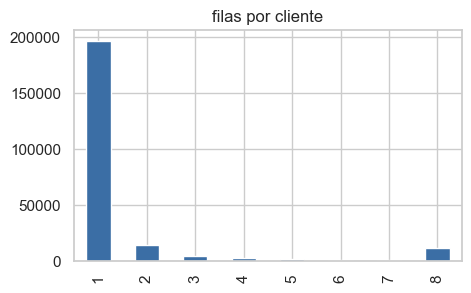

In [2]:
from src.features_static import _split_types

tr = utils.load_raw("sunat_train")
y = utils.load_target()
key = utils.find_col(tr, "key", required=True)
n_dup = tr.duplicated().sum()
print(tr.shape, f"| duplicadas exactas: {n_dup:,} ({n_dup / len(tr):.1%})")
tr.groupby(key).size().clip(upper=8).value_counts().sort_index().plot.bar(figsize=(5, 3), color="#3b6ea5", title="filas por cliente")
plt.show()

## Variables

numericas: ['fecalta', 'fecbaja']
         ubigeo  cargorele  ciiu  tipcontribuyente  codzona  codvia  facturacion  condiciondomicilio  comercioexterior  estadocontribuyente  contabilidad  codentidadtributo  tippersona  domiciliado  estadotributo
niveles    1655        656   285                50       36      29           21                  15                14                   13            12                  9           3            3              3


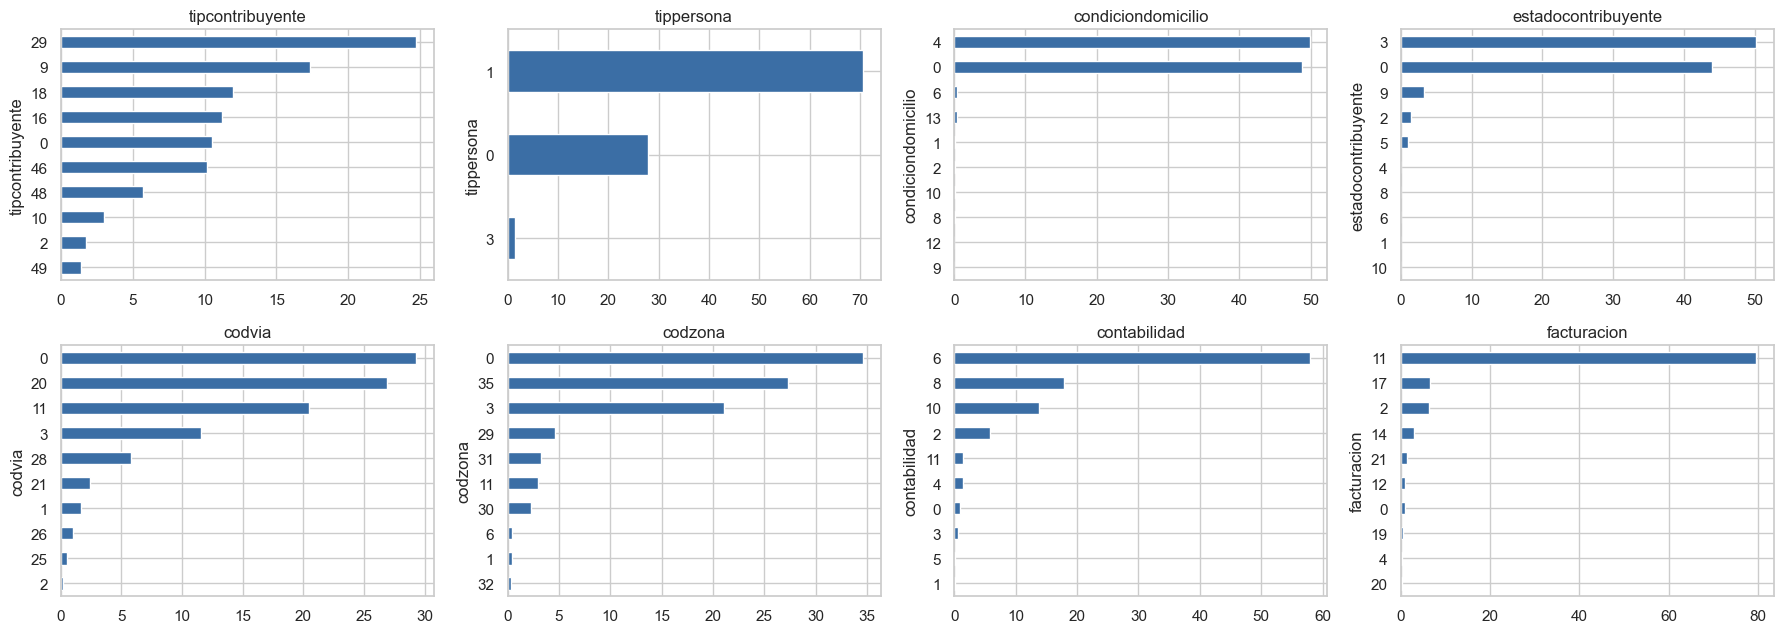

In [3]:
_, cats, nums = _split_types(tr.drop(columns=[key]))
print("numericas:", nums)
print(tr[cats].nunique().sort_values(ascending=False).to_frame("niveles").T.to_string())
fig, axes = plt.subplots(2, 4, figsize=(18, 6.5))
for ax, c in zip(axes.ravel(), [c for c in cats if tr[c].nunique() <= 60][:8]):
    tr[c].value_counts(normalize=True).head(10)[::-1].mul(100).plot.barh(ax=ax, color="#3b6ea5")
    ax.set_title(c)
plt.tight_layout()
plt.show()

## Construcción de variables

In [4]:
del tr
pipeline.run_static("sunat")
X, uni = eda.source_univariate("sunat", y)
print(X.shape)
has = y.index.isin(X.index)
print(f"con registro: {has.mean():.1%} | default con registro {y[has].mean():.2%} | sin registro {y[~has].mean():.2%}")
uni.head(15)

00:06:05 | INFO | sunat: 2 numéricas, 15 categóricas, 0 fechas
00:06:45 | INFO | sunat: se eliminan 11 numéricas constantes o casi vacías
00:07:44 | INFO | SUNAT listo: train (233866, 116) | test (253803, 116)


(233866, 115)
con registro: 65.2% | default con registro 14.77% | sin registro 17.79%


,variable,auc_univariado,iv,nulos_pct,lectura_iv
0,sunat_ubigeo_moda,NaN,0.119396,0.0,media
1,sunat_ciiu_moda,NaN,0.062375,0.0,débil
2,sunat_fecalta_min,0.546786,0.033140,8.5,débil
3,sunat_estadotributo_n_2,0.527018,0.032557,0.0,débil
4,sunat_codentidadtributo_n_8,0.527018,0.032557,0.0,débil
5,sunat_fecalta_mean,0.541324,0.025148,8.5,débil
6,sunat_condiciondomicilio_n_0,0.525509,0.022857,0.4,débil
7,sunat_fecalta_std,0.544284,0.022839,87.4,débil
8,sunat_fecalta_n_con_dato,0.528269,0.019067,0.0,inútil
9,sunat_codzona_moda,NaN,0.018902,0.0,inútil


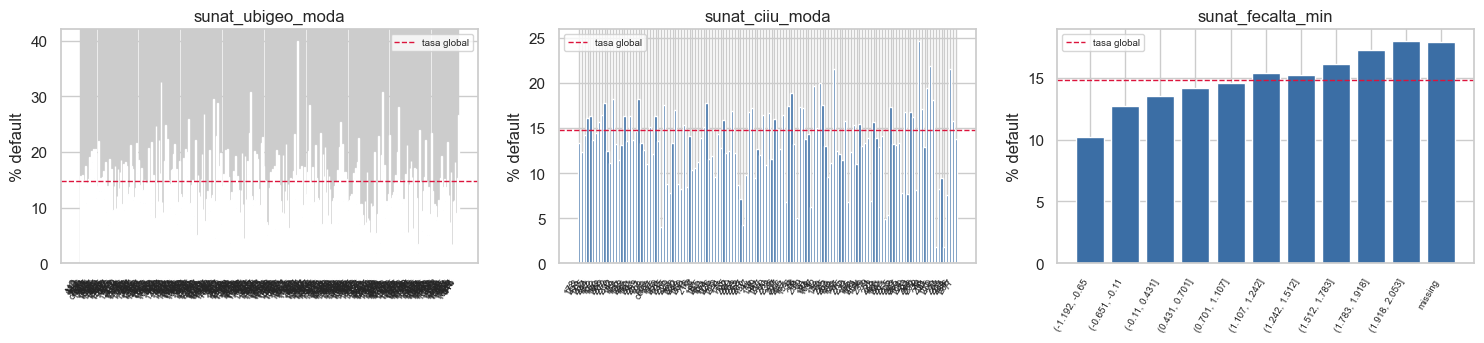

In [5]:
top = uni.variable.head(3).tolist()
idx = X.index.intersection(y.index)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, c in zip(axes, top):
    eda.default_rate_by_bin(X.loc[idx, c], y.loc[idx], ax=ax)
plt.tight_layout()
plt.show()